# Algebras, symmetry and pictures with SpynDynamica

Tools of [SpynDynamica](spyndynamica.ipynb), the Python port in progress of
[SpinDynamica](https://www.spindynamica.soton.ac.uk), that answer structural questions about a spin system:
which operators commute with a Hamiltonian, which operators a set of Hamiltonians can generate, what a
density operator can and cannot be turned into, and how the states split under spin permutations. The last
section draws tensors, axis systems and rotations in three dimensions. The SpinDynamica names are listed in
[Coming from SpinDynamica](coming-from-spindynamica.ipynb).

SpinDynamica is the work of Malcolm H. Levitt and co-authors. Work that uses SpynDynamica should cite
C. Bengs, M. H. Levitt, *SpinDynamica: Symbolic and numerical magnetic resonance in a Mathematica environment*, Magn. Reson. Chem. (2017), doi:10.1002/mrc.4642.

*Generated from [`docs/spyndynamica-symmetry.md`](../spyndynamica-symmetry.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Commutants](#Commutants)
2. [Lie algebras and accessible operators](#Lie-algebras-and-accessible-operators)
3. [Abelian subalgebras](#Abelian-subalgebras)
4. [Permutation groups and symmetry-adapted bases](#Permutation-groups-and-symmetry-adapted-bases)
5. [Permutation and rotation symmetry together](#Permutation-and-rotation-symmetry-together)
6. [Pictures in three dimensions](#Pictures-in-three-dimensions)

## Commutants

`commutant(operators)` returns operators that span everything that commutes with all the given ones: the
constants of the motion under those Hamiltonians. The coefficients must be numbers; the linear algebra is
exact, so the result is readable.

In [1]:
import sympy as sp

from spyndynamica import SpinSystem, bicommutant, commutant

s = SpinSystem(2)
I = s.I
total_z, coupling = I(None, "z"), s.dot(1, 2)

print(*commutant([total_z]), sep="  |  ")
print(*commutant([coupling, total_z]), sep="  |  ")
print(*commutant([I(1, "z")], [I(1, "x"), I(1, "y"), I(1, "z"), I(2, "x"), I(2, "y"), I(2, "z")]), sep="  |  ")

I1x I2x + I*I1x I2y - I*I1y I2x + I1y I2y  |  I1x I2x - I*I1x I2y + I*I1y I2x + I1y I2y  |  I1z I2z  |  I1z  |  I2z  |  1
I1x I2x + I1y I2y  |  I1z I2z  |  I2z + I1z  |  1
I1z  |  I2x  |  I2y  |  I2z


The list is one basis of the commutant among many. A second argument restricts the search to the combinations
of the operators in it. `bicommutant` is the commutant of the commutant, the algebra that the operators
generate together with the unity operator:

In [2]:
print(*bicommutant([total_z]), sep="  |  ")

I1z I2z  |  I2z + I1z  |  1


## Lie algebras and accessible operators

`lie_algebra(generators)` closes a set of traceless operators under `−i[A, B]`. The generators come first, then
the commutators as they are found. Two spins with pulses on each and a weak coupling generate all 15
traceless operators, so every unitary transformation of the pair can be made; total-spin pulses and a scalar
coupling generate four.

In [3]:
from spyndynamica import inaccessible, lie_algebra

print(*lie_algebra([I(1, "x"), I(1, "y")]), sep="  |  ")
weak = [I(1, "x"), I(1, "y"), I(2, "x"), I(2, "y"), I(1, "z") @ I(2, "z")]
print(len(lie_algebra(weak)), len(lie_algebra([I(None, "x"), I(None, "y"), coupling])))

I1x  |  I1y  |  I1z
15 4


Linear independence is counted over the real numbers, which suits Hermitian generators; `field="C"` counts
over the complex numbers. `inaccessible(source, targets, hamiltonians)` asks the question that matters for a
density operator: whether a target can be reached from the source by any sequence of evolution under the
Hamiltonians. Magnetisation cannot become singlet order as long as the Hamiltonians treat the two spins alike,
and can once a shift difference is available:

In [4]:
print(inaccessible(total_z, coupling, [I(None, "x"), I(None, "y"), coupling]))
difference = I(1, "z") - I(2, "z")
print(inaccessible(total_z, [coupling, difference], [I(None, "x"), I(None, "y"), coupling, difference]))

True
[False, False]


## Abelian subalgebras

`abelian_subalgebra(operators)` extends commuting Hermitian operators to a maximal set of commuting Hermitian
operators, and `is_maximal_abelian` says whether a set is one already. Such a set labels the states: its
common eigenbasis is unique.

In [5]:
from spyndynamica import abelian_subalgebra, is_maximal_abelian

print(*abelian_subalgebra([total_z]), sep="  |  ")
print(is_maximal_abelian([I(1, "z"), I(2, "z")]), is_maximal_abelian([I(1, "z"), I(2, "z"), I(1, "z") @ I(2, "z")]))

I2z + I1z  |  I1x I2x + I1y I2y  |  I1z I2z
False True


Both take a second argument that restricts them to the combinations of a list of operators, as `commutant`
does.

## Permutation groups and symmetry-adapted bases

`spin_permutation_group(s, (name, degree))` gives the spin permutation operators of the symmetric,
alternating, cyclic or dihedral group, and `permutation_group` the permutations as cycles. A group can also be
given as a list of permutations.

In [6]:
from spyndynamica import permutation_group, spin_permutation_group, symmetry_adapted_basis

three = SpinSystem(3)
print(permutation_group("SymmetricGroup", 3))
cycle = spin_permutation_group(three, ("CyclicGroup", 3))[1]
print(cycle @ three.I(1, "z") @ cycle.dagger())

[(), ((1, 2),), ((1, 3),), ((2, 3),), ((1, 2, 3),), ((1, 3, 2),)]
I2z


`symmetry_adapted_basis(s, group)` builds kets that belong to irreducible representations of the group and are
eigenkets of the total angular momentum and of its z component. Every group operator is block diagonal in that
basis, each block is an irreducible representation, and equivalent representations have the same matrices.
`basis.quantum_numbers` lists `(irrep, dimension, J, M, copy, partner)` for every ket. The default group is
the symmetric group of all spins.

In [7]:
import numpy as np

adapted = symmetry_adapted_basis(three)
for irrep, dimension, J, M, copy, partner in adapted.quantum_numbers:
    print(f"irrep {irrep} of dimension {dimension}: J = {J}, M = {M}, partner {partner}")

exchange_12 = spin_permutation_group(three, ("SymmetricGroup", 3))[1]
print(np.abs(exchange_12.numeric(basis=adapted)).round(3))

irrep 0 of dimension 1: J = 3/2, M = 3/2, partner 0
irrep 0 of dimension 1: J = 3/2, M = 1/2, partner 0
irrep 0 of dimension 1: J = 3/2, M = -1/2, partner 0
irrep 0 of dimension 1: J = 3/2, M = -3/2, partner 0
irrep 1 of dimension 2: J = 1/2, M = 1/2, partner 0
irrep 1 of dimension 2: J = 1/2, M = 1/2, partner 1
irrep 1 of dimension 2: J = 1/2, M = -1/2, partner 0
irrep 1 of dimension 2: J = 1/2, M = -1/2, partner 1
[[1.    0.    0.    0.    0.    0.    0.    0.   ]
 [0.    1.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    1.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    1.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.676 0.737 0.    0.   ]
 [0.    0.    0.    0.    0.737 0.676 0.    0.   ]
 [0.    0.    0.    0.    0.    0.    0.676 0.737]
 [0.    0.    0.    0.    0.    0.    0.737 0.676]]


Three spins-1/2 give the totally symmetric quartet and two doublets that form a two-dimensional
representation: the permutation of spins 1 and 2 mixes the two partners and leaves `M` alone. The basis is
numeric. The kets within a representation of dimension above 1, and the copies of a representation that
occurs more than once, are a choice, and the choice is the same in every session.

## Permutation and rotation symmetry together

For equal spins the two symmetries are tied to each other: the kets that transform under one irreducible
representation of the symmetric group have fixed total angular momenta. `dual_pairing(n, j)` lists them for
`n` spins `j`, by the Young diagram of the representation as its row lengths.

In [8]:
from spyndynamica import dual_pairing

print(dual_pairing(3, sp.Rational(1, 2)))
print(dual_pairing(4, sp.Rational(1, 2)))
print(dual_pairing(3, 1))

{(3,): {3/2: 1}, (2, 1): {1/2: 1}}
{(4,): {2: 1}, (3, 1): {1: 1}, (2, 2): {0: 1}}
{(3,): {3: 1, 1: 1}, (2, 1): {2: 1, 1: 1}, (1, 1, 1): {0: 1}}


Four spins-1/2 have a quintet in the symmetric representation `(4,)`, three triplets in `(3, 1)` and two
singlets in `(2, 2)`; these are the nuclear spin isomers of a molecule such as methane.

## Pictures in three dimensions

The drawing routines return a `Scene`: surfaces, lines, arrows and labels as plain arrays. Scenes add up, and
`translated`, `rotated_euler` and `rotated_polar` move them as the routines of the same names move vectors.
`scene.figure()` gives a Plotly figure; Plotly is needed for that step only.

`ovaloid(tensor, center)` draws a rank-2 tensor as the surface whose distance from the centre in every
direction is the value of the tensor along that direction, positive lobes in one colour and negative lobes in
another. It takes a 3 × 3 matrix, of which it uses the symmetric traceless part, or the five components of a
spherical tensor; `isotropic=True` adds the isotropic part, and `scale` converts tensor values into lengths.

In [9]:
from spyndynamica import axes_3d, ovaloid, ovaloid_radius

shielding = np.array([[30.0, 4.0, 0.0], [4.0, -10.0, 6.0], [0.0, 6.0, -20.0]])
print(ovaloid_radius(shielding, [0, np.pi / 2], [0, 0]).round(2))
print(ovaloid(shielding, scale=0.02).surfaces[0].vertices.shape)

[-20.  30.]
(3321, 3)


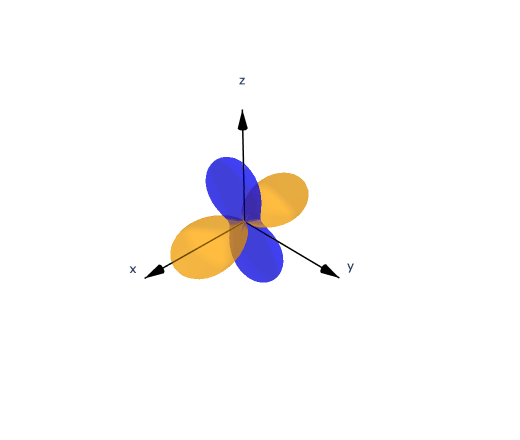

In [10]:
# a plotly figure of the tensor with the laboratory axes
(ovaloid(shielding, scale=0.02) + axes_3d(length=0.8)).figure(width=520, height=440)

`axes_3d(axes, origin)` draws an axis system given as for `axis_system`, and `visualize_euler(angles)` the
laboratory axes with the system whose Euler angles relative to them are the angles. `l_shape()` is a block
that shows the sense of a rotation, `rotor()` a sample rotor and `sphere_and_axes()` a unit sphere for
trajectories.

In [11]:
from spyndynamica import axes_to_euler, visualize_euler

angles = (0.3, 0.7, -0.4)
tilted = [arrow.end for arrow in visualize_euler(angles).arrows[3:]]
print(np.round(axes_to_euler(tilted), 3))

[ 0.3  0.7 -0.4]


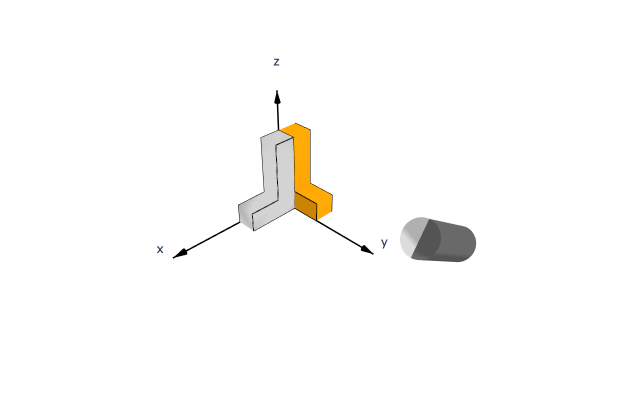

In [12]:
# a plotly figure: an L shape before and after a quarter turn about z, and a rotor at the magic angle
from spyndynamica import l_shape, rotor

magic = np.arccos(1 / np.sqrt(3))
before = l_shape() + axes_3d(length=1.2)
after = l_shape(color="orange").rotated_euler((np.pi / 2, 0, 0))
spinner = rotor(radius=0.15, length=0.7).rotated_euler((0, magic, 0)).translated([0.0, 1.8, 0.5])
(before + after + spinner).figure(width=620, height=420)